# Librerias

In [30]:
import pandas as pd
import numpy as np
import tensorflow as tf

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

# Lectura de Datos

In [31]:
df = pd.read_csv('C:\\Users\\richa\\Desktop\\UNAMBA\\SEMESTRES\\SEMESTRE VIII\\FUNDAMENTOS DE IA\\CODIGO\\data\\datos_estudiantes.csv')

df.head()



,horas_estudio,asistencia,resultado
0,3.75,75.83,0
1,9.51,2.46,0
2,7.32,2.21,0
3,5.99,32.36,0
4,1.56,48.86,0


# Separacion X e Y

In [32]:

X = df[['horas_estudio', 'asistencia']].to_numpy(dtype=np.float32)
Y = df[['resultado']].to_numpy(dtype=np.float32)

print(X)
print(Y)

[[ 3.75 75.83]
 [ 9.51  2.46]
 [ 7.32  2.21]
 ...
 [ 9.69  2.54]
 [ 7.5  64.58]
 [ 1.3  63.69]]
[[0.]
 [0.]
 [0.]
 ...
 [1.]
 [0.]
 [0.]]


# Division de datos train, test y evaluacion

In [33]:
X_temp, X_test, Y_temp, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

X_train, X_val, Y_train, Y_val = train_test_split(X_temp, Y_temp, test_size=0.2, random_state=42) 

X_train.shape, X_val.shape, X_test.shape

((768, 2), (192, 2), (240, 2))

# Estandarizar los datos

In [34]:
estandarizador = StandardScaler()

X_train = estandarizador.fit_transform(X_train).astype(np.float32)
X_val = estandarizador.transform(X_val).astype(np.float32)
X_test = estandarizador.transform(X_test).astype(np.float32)

X_train

array([[-0.41399467,  0.06861877],
       [-0.35924265,  1.0663648 ],
       [ 1.0232432 ,  0.774384  ],
       ...,
       [-0.9375599 , -0.3848388 ],
       [-1.5124551 ,  0.17511001],
       [-0.59878236,  1.5372229 ]], shape=(768, 2), dtype=float32)

# Redes neuronales profundas

In [35]:
class MLP(tf.keras.Model):
    def __init__(self):
        super().__init__()  

    # creando la primera capa oculta con 20 neuronas y función de activación
        self.capa_oculta1 = tf.keras.layers.Dense(20, activation='relu', name='capa_oculta1')

    # creando la segunda capa oculta con 20 neuronas y función de activación
        self.capa_oculta2 = tf.keras.layers.Dense(20, activation='relu', name='capa_oculta2')

    # crenado la capa de salida con 1 neurona y función de activación sigmoide
        self.capa_salida = tf.keras.layers.Dense(1, activation='sigmoid', name='capa_salida')

    def call(self, entradas, training=False):
        x = self.capa_oculta1(entradas)
        x = self.capa_oculta2(x)
        return self.capa_salida(x)

# Crear y ejecutar el Modelo

In [36]:

modelo = MLP()

modelo(tf.zeros((1,2)))

# definir la función de pérdida y el learnig rate

optimizador = tf.keras.optimizers.Adam(learning_rate=0.001)

modelo.compile(optimizer=optimizador, loss='binary_crossentropy', metrics=['accuracy'])

modelo.summary()

Model: "mlp_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ capa_oculta1 (Dense)            │ (1, 20)                │            60 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ capa_oculta2 (Dense)            │ (1, 20)                │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ capa_salida (Dense)             │ (1, 1)                 │            21 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 501 (1.96 KB)

 Trainable params: 501 (1.96 KB)

 Non-trainable params: 0 (0.00 B)

In [37]:
historial = modelo.fit(X_train, Y_train, validation_data=(X_val, Y_val), epochs=100, batch_size=32)

Epoch 1/100


24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.4505 - loss: 0.7034 - val_accuracy: 0.7917 - val_loss: 0.6434
Epoch 2/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8477 - loss: 0.5957 - val_accuracy: 0.8125 - val_loss: 0.5432
Epoch 3/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8203 - loss: 0.4955 - val_accuracy: 0.7865 - val_loss: 0.4612
Epoch 4/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8138 - loss: 0.4212 - val_accuracy: 0.7969 - val_loss: 0.4133
Epoch 5/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8359 - loss: 0.3775 - val_accuracy: 0.8073 - val_loss: 0.3868
Epoch 6/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8438 - loss: 0.3514 - val_accuracy: 0.8177 - val_loss: 0.3715
Epoch 7/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8424 - loss: 0.3334 - val_accuracy: 0.7969 - val_loss: 0.3617
Epoch 8/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8398 - loss: 0.3228 - val_accuracy: 0.7969 - val_loss: 0.

# Graficar Funcion de perdida

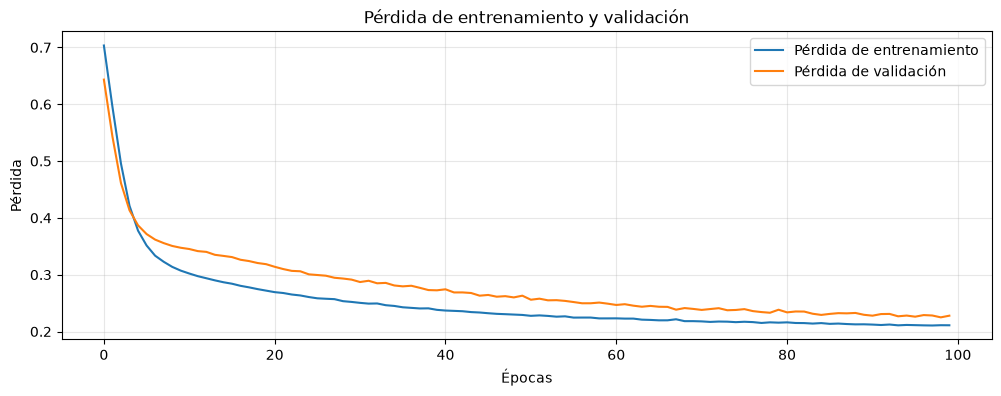

In [38]:
#grafico de función de pérdida y precisión

plt.figure(figsize=(12, 4))
plt.plot(historial.history['loss'], label='Pérdida de entrenamiento')
plt.plot(historial.history['val_loss'], label='Pérdida de validación')
plt.title('Pérdida de entrenamiento y validación')
plt.xlabel('Épocas')
plt.ylabel('Pérdida')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

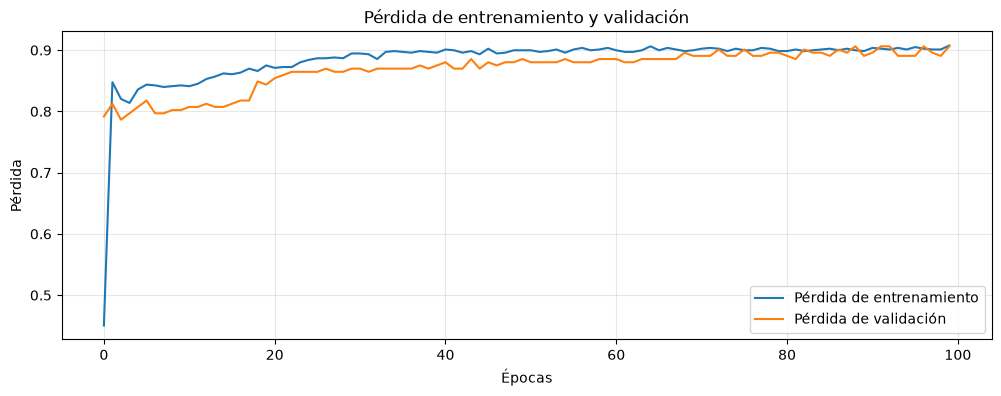

In [39]:

plt.figure(figsize=(12, 4))
plt.plot(historial.history['accuracy'], label='Pérdida de entrenamiento')
plt.plot(historial.history['val_accuracy'], label='Pérdida de validación')
plt.title('Pérdida de entrenamiento y validación')
plt.xlabel('Épocas')
plt.ylabel('Pérdida')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [40]:
resultados = modelo.evaluate(X_test, Y_test, verbose=0)
print(f"Pérdida: {resultados[0]}, Precisión: {resultados[1]}")

Pérdida: 0.2184770256280899, Precisión: 0.8958333134651184


# Matriz de confusion

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
Matriz de confusión:
[[186   7]
 [ 18  29]]


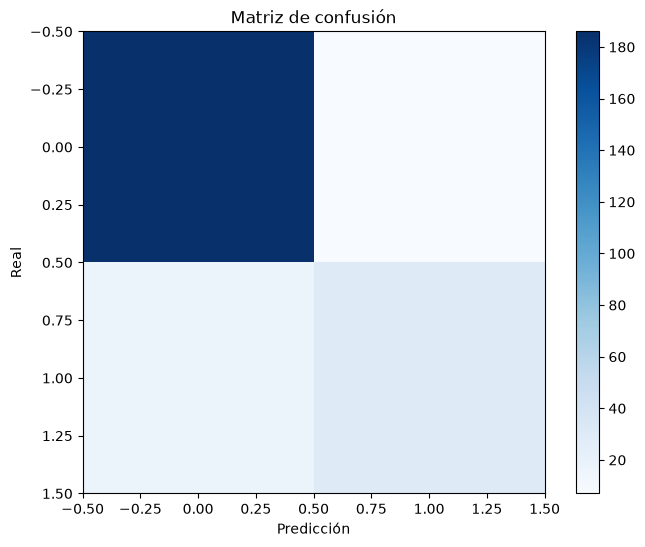

Reporte de clasificación:
              precision    recall  f1-score   support

 No Aprobado       0.91      0.96      0.94       193
    Aprobado       0.81      0.62      0.70        47

    accuracy                           0.90       240
   macro avg       0.86      0.79      0.82       240
weighted avg       0.89      0.90      0.89       240



In [48]:
Y_pred = modelo.predict(X_test)
print("Matriz de confusión:")
print(confusion_matrix(Y_test, (Y_pred > 0.5).astype(int)))

plt.figure(figsize=(8, 6))
plt.imshow(confusion_matrix(Y_test, (Y_pred > 0.5).astype(int)), interpolation='nearest', cmap=plt.cm.Blues)
plt.title('Matriz de confusión')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.colorbar()
plt.show()

print("Reporte de clasificación:")
print(
    classification_report(
        Y_test.astype(int).ravel(),
        (Y_pred > 0.5).astype(int).ravel(),
        target_names=['No Aprobado', 'Aprobado']
    )
)